# Random baseline: 100,000 Jev ratings

This summarizes `random-baseline-100k`, where `CompatibleRandomMatcher` showed simulated users random compatible profiles and Jev rated each one. It's the baseline a real matcher has to beat.

A rating's score is Jev's probability that the rater likes the target. A pair's **match chance** is the product of their two scores, for pairs who rated each other.

This notebook only reads saved data, so it makes no API calls and costs nothing to re-run. It saves its numbers to `exports/random-baseline-100k_metrics.json` and its charts to `notebooks/figures/`.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from manager import ProfileManager
from paths import MAIN_DB, PERSONA_DB
from raters import JEV_PRICE_PER_MTOK

RUN_ID = "random-baseline-100k"
SEED = 42
N_BOOTSTRAP = 2000
METRICS_PATH = ROOT / "exports" / f"{RUN_ID}_metrics.json"
FIGURE_DIR = ROOT / "notebooks" / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.bottom": False,
    "ytick.left": False,
    "text.color": INK,
    "font.size": 10,
    "figure.dpi": 120,
})


def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / f"random_baseline_{name}.png", dpi=160, bbox_inches="tight")


manager = ProfileManager(MAIN_DB, PERSONA_DB)
profiles = {p.user_id: p for p in manager.list_profiles()}
ratings = pd.DataFrame([r.model_dump() for r in manager.ratings_in_run(RUN_ID)])
transcripts = manager.transcripts_in_run(RUN_ID)
tokens = np.array([json.loads(t.raw_output)["input_tokens"] for t in transcripts])
run = manager.get_run(RUN_ID)

for column in ("looking_for", "religion", "gender", "interested_in"):
    ratings[f"rater_{column}"] = ratings["rater_id"].map(lambda u, c=column: getattr(profiles[u], c))
    ratings[f"target_{column}"] = ratings["target_id"].map(lambda u, c=column: getattr(profiles[u], c))
ratings["same_goal"] = ratings["rater_looking_for"] == ratings["target_looking_for"]
ratings["same_religion"] = ratings["rater_religion"] == ratings["target_religion"]

## 1. Did the run go as planned?

In [2]:
duration_hours = (run.finished_at - run.started_at).total_seconds() / 3600
health = {
    "Steps attempted": int(ratings["step"].max()),
    "Ratings saved": len(ratings),
    "Failed steps": int(ratings["step"].max()) - len(ratings),
    "Pairs rated twice": int(ratings.duplicated(["rater_id", "target_id"]).sum()),
    "Ratings without a transcript": len(ratings) - len(transcripts),
    "Raters": ratings["rater_id"].nunique(),
    "Targets": ratings["target_id"].nunique(),
    "Models used": ", ".join(sorted(ratings["model_version"].unique())),
    "Input tokens per rating": round(float(tokens.mean())),
    "Jev cost (USD)": round(float(tokens.sum() / 1e6 * JEV_PRICE_PER_MTOK), 2),
    "Hours from first start to finish, including the pause": round(duration_hours, 2),
}
per_rater = ratings.groupby("rater_id").size()
per_target = ratings.groupby("target_id").size()
health["Ratings given per user (min, median, max)"] = f"{per_rater.min()}, {per_rater.median():.0f}, {per_rater.max()}"
health["Ratings received per user (min, median, max)"] = f"{per_target.min()}, {per_target.median():.0f}, {per_target.max()}"
pd.Series(health, name="value").to_frame()

,value
Steps attempted,100000
Ratings saved,99999
Failed steps,1
Pairs rated twice,0
Ratings without a transcript,0
Raters,2000
Targets,2000
Models used,jev-1.14.0
Input tokens per rating,752
Jev cost (USD),3.16


## 2. How often do people like who they're shown?

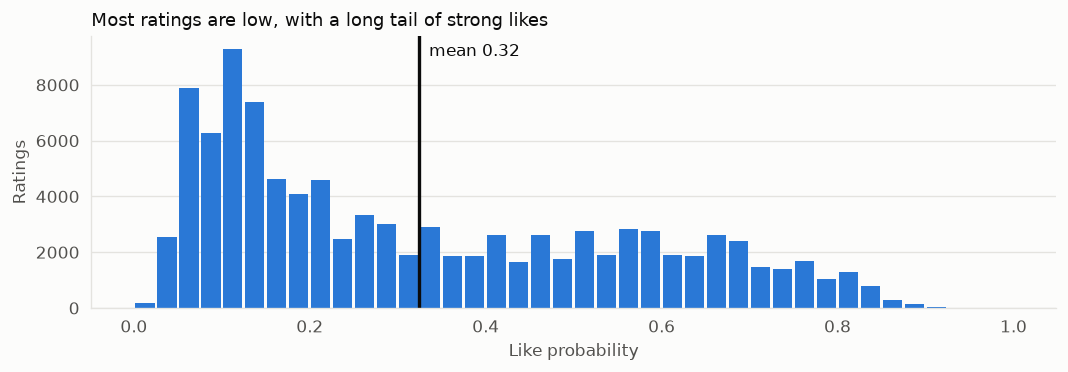

95% interval for the mean, by rater: 0.318 to 0.330


,value
Mean like probability,0.324
SD,0.232
Median,0.250
Share at 0.3 or below,0.557
Share at 0.5 or above,0.271
Share at 0.7 or above,0.089


In [3]:
score = ratings["score"]
rng = np.random.default_rng(SEED)


def bootstrap_mean(groups, n=N_BOOTSTRAP):
    groups = np.asarray(groups)
    samples = rng.choice(groups, size=(n, len(groups)), replace=True).mean(axis=1)
    return np.percentile(samples, [2.5, 97.5])


rater_means = ratings.groupby("rater_id")["score"].mean()
mean_interval = bootstrap_mean(rater_means.values)
likes = {
    "Mean like probability": score.mean(),
    "SD": score.std(),
    "Median": score.median(),
    "Share at 0.3 or below": (score <= 0.3).mean(),
    "Share at 0.5 or above": (score >= 0.5).mean(),
    "Share at 0.7 or above": (score >= 0.7).mean(),
}
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(score, bins=np.linspace(0, 1, 41), color=BLUE, rwidth=0.88)
ax.axvline(score.mean(), color=INK, linewidth=2)
ax.annotate(f"mean {score.mean():.2f}", (score.mean(), ax.get_ylim()[1]), xytext=(6, -12), textcoords="offset points")
ax.set_xlabel("Like probability")
ax.set_ylabel("Ratings")
ax.grid(axis="x", visible=False)
ax.set_title("Most ratings are low, with a long tail of strong likes")
fig.tight_layout()
save_figure(fig, "like_probability")
plt.show()
print(f"95% interval for the mean, by rater: {mean_interval[0]:.3f} to {mean_interval[1]:.3f}")
pd.Series(likes, name="value").round(3).to_frame()

## 3. How many matches does random matching produce?

Most random pairs never rate each other, so only some ratings can contribute to a match. **This is the number a real matcher should improve most.** It can raise matches both by making pairs rate each other more often and by picking pairs more likely to say yes. Thresholds are shown too, since the right cut-off depends on how you later define a match.

In [4]:
score_of = dict(zip(zip(ratings["rater_id"], ratings["target_id"]), ratings["score"]))
pairs = pd.DataFrame(
    [(a, b, s, score_of[(b, a)]) for (a, b), s in score_of.items() if a < b and (b, a) in score_of],
    columns=["user_a", "user_b", "score_a", "score_b"],
)
pairs["match_chance"] = pairs["score_a"] * pairs["score_b"]
match_interval = bootstrap_mean(pairs["match_chance"].values)
swipes = np.random.default_rng(SEED)
simulated = (swipes.random(len(pairs)) < pairs["score_a"]) & (swipes.random(len(pairs)) < pairs["score_b"])
matches = {
    "Ratings": len(ratings),
    "Pairs who rated each other": len(pairs),
    "Share of ratings in such a pair": 2 * len(pairs) / len(ratings),
    "Expected matches": pairs["match_chance"].sum(),
    "Expected matches per 1,000 ratings": pairs["match_chance"].sum() / len(ratings) * 1000,
    "Match chance per pair (mean)": pairs["match_chance"].mean(),
    "Match chance if the two scores were unrelated": pairs["score_a"].mean() * pairs["score_b"].mean(),
    "Correlation between the two scores in a pair": pairs["score_a"].corr(pairs["score_b"]),
    "Pairs with both at 0.5 or above": int(((pairs["score_a"] >= 0.5) & (pairs["score_b"] >= 0.5)).sum()),
    "Pairs with both at 0.7 or above": int(((pairs["score_a"] >= 0.7) & (pairs["score_b"] >= 0.7)).sum()),
    "One seeded draw of simulated swipes: matches": int(simulated.sum()),
}
print(f"95% interval for match chance per pair: {match_interval[0]:.3f} to {match_interval[1]:.3f}")
pd.Series(matches, name="value").round(3).to_frame()

95% interval for match chance per pair: 0.128 to 0.139


,value
Ratings,99999.000
Pairs who rated each other,3104.000
Share of ratings in such a pair,0.062
Expected matches,413.979
"Expected matches per 1,000 ratings",4.140
Match chance per pair (mean),0.133
Match chance if the two scores were unrelated,0.108
Correlation between the two scores in a pair,0.467
Pairs with both at 0.5 or above,415.000
Pairs with both at 0.7 or above,62.000


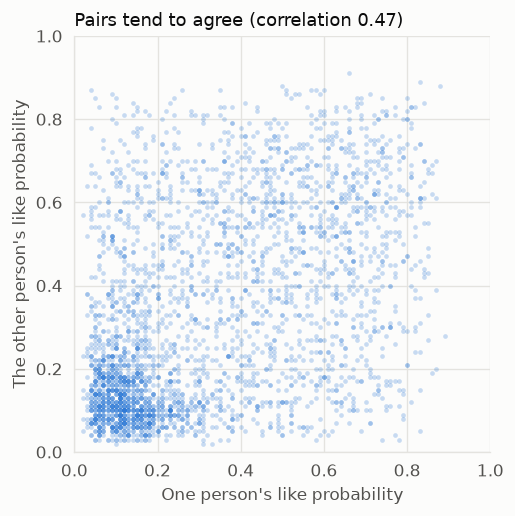

In [5]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(pairs["score_a"], pairs["score_b"], s=8, color=BLUE, alpha=0.25, linewidths=0)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("One person's like probability")
ax.set_ylabel("The other person's like probability")
ax.set_title(f"Pairs tend to agree (correlation {matches['Correlation between the two scores in a pair']:.2f})")
fig.tight_layout()
save_figure(fig, "pair_scores")
plt.show()

## 4. What drives the ratings?

These are simple averages rather than a model, so fields can overlap. Picky raters and popular targets are measured from about 50 ratings per person, so some of their spread is sampling variation.

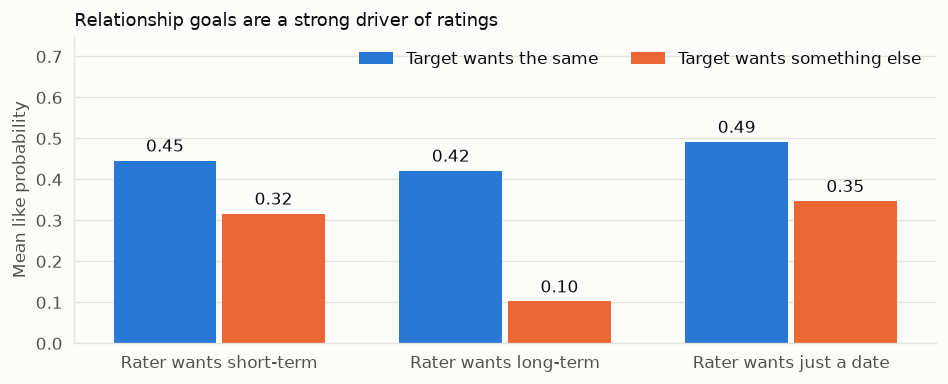

                          yes     no  difference
Same relationship goal  0.455  0.258       0.197
Same religion           0.412  0.315       0.097

Mean like probability by the rater's goal (rows) and the target's goal (columns):
target_looking_for  short-term  long-term  just a date
rater_looking_for                                     
short-term               0.446      0.163        0.453
long-term                0.091      0.422        0.114
just a date              0.422      0.261        0.492

By rater's gender and interest:
                                   size   mean
rater_gender rater_interested_in              
man          men                    812  0.327
             women                50227  0.354
woman        men                  48540  0.293
             women                  420  0.334


In [6]:
goals = ["short-term", "long-term", "just a date"]
goal_table = ratings.pivot_table(index="rater_looking_for", columns="target_looking_for", values="score").loc[goals, goals]

fig, ax = plt.subplots(figsize=(8, 3.3))
x = np.arange(len(goals))
width = 0.36
same = [ratings[(ratings["rater_looking_for"] == g) & ratings["same_goal"]]["score"].mean() for g in goals]
different = [ratings[(ratings["rater_looking_for"] == g) & ~ratings["same_goal"]]["score"].mean() for g in goals]
for offset, values, color, label in ((-width / 2 - 0.01, same, BLUE, "Target wants the same"), (width / 2 + 0.01, different, ORANGE, "Target wants something else")):
    bars = ax.bar(x + offset, values, width, color=color, label=label)
    ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xticks(x, [f"Rater wants {g}" for g in goals])
ax.set_ylim(0, 0.75)
ax.set_ylabel("Mean like probability")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncols=2, loc="upper right")
ax.set_title("Relationship goals are a strong driver of ratings")
fig.tight_layout()
save_figure(fig, "relationship_goals")
plt.show()

drivers = pd.DataFrame({
    "yes": [ratings[ratings["same_goal"]]["score"].mean(), ratings[ratings["same_religion"]]["score"].mean()],
    "no": [ratings[~ratings["same_goal"]]["score"].mean(), ratings[~ratings["same_religion"]]["score"].mean()],
}, index=["Same relationship goal", "Same religion"])
drivers["difference"] = drivers["yes"] - drivers["no"]
print(drivers.round(3).to_string())
print()
print("Mean like probability by the rater's goal (rows) and the target's goal (columns):")
print(goal_table.round(3).to_string())
print()
print("By rater's gender and interest:")
print(ratings.groupby(["rater_gender", "rater_interested_in"])["score"].agg(["size", "mean"]).round(3).to_string())

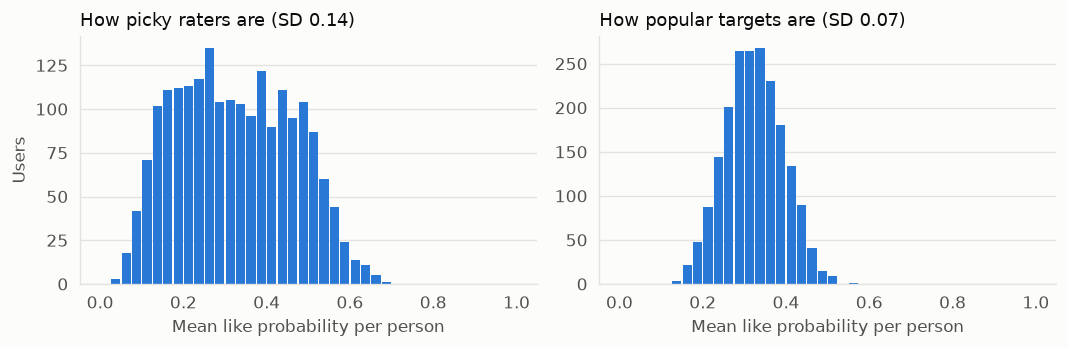

In [7]:
target_means = ratings.groupby("target_id")["score"].mean()
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
for ax, values, title in ((axes[0], rater_means, "How picky raters are"), (axes[1], target_means, "How popular targets are")):
    ax.hist(values, bins=np.linspace(0, 1, 41), color=BLUE, rwidth=0.88)
    ax.set_title(f"{title} (SD {values.std():.2f})")
    ax.set_xlabel("Mean like probability per person")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Users")
fig.tight_layout()
save_figure(fig, "raters_and_targets")
plt.show()

## 5. Does anything change over the run?

A random matcher learns nothing, so this should be flat. A real matcher's curve should rise above it.

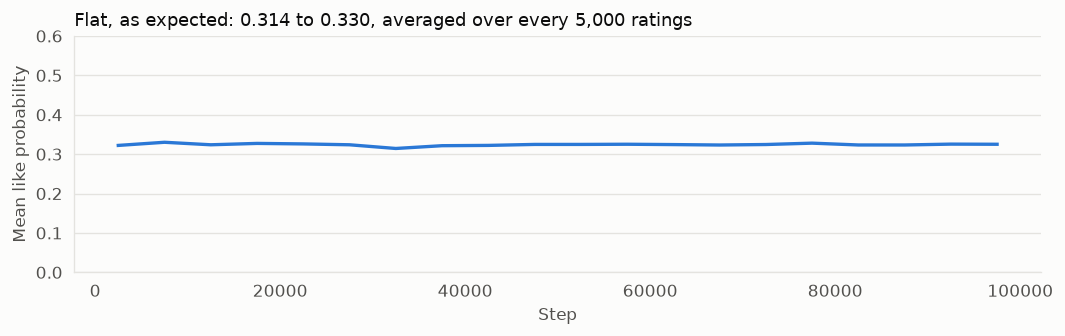

In [8]:
ordered = ratings.sort_values("step")
window = 5000
curve = ordered["score"].groupby(np.arange(len(ordered)) // window).mean()
steps = (curve.index + 0.5) * window

fig, ax = plt.subplots(figsize=(9, 2.9))
ax.plot(steps, curve.values, color=BLUE, linewidth=2)
ax.set_ylim(0, 0.6)
ax.set_xlabel("Step")
ax.set_ylabel("Mean like probability")
ax.grid(axis="x", visible=False)
ax.set_title(f"Flat, as expected: {curve.min():.3f} to {curve.max():.3f}, averaged over every {window:,} ratings")
fig.tight_layout()
save_figure(fig, "learning_curve")
plt.show()

## Saved baseline numbers

In [9]:
def plain(value):
    return value.item() if hasattr(value, "item") else value


baseline = {
    "run_id": RUN_ID,
    "matcher": run.matcher_name,
    "health": {k: plain(v) for k, v in health.items()},
    "likes": {k: plain(v) for k, v in likes.items()},
    "mean_like_95_interval": [float(v) for v in mean_interval],
    "matches": {k: plain(v) for k, v in matches.items()},
    "match_chance_95_interval": [float(v) for v in match_interval],
    "same_goal_difference": float(drivers.loc["Same relationship goal", "difference"]),
    "same_religion_difference": float(drivers.loc["Same religion", "difference"]),
    "learning_curve_every_5000": [float(v) for v in curve.values],
}
METRICS_PATH.write_text(json.dumps(baseline, indent=2))
print("Saved to", METRICS_PATH.relative_to(ROOT))

Saved to exports/random-baseline-100k_metrics.json


## What this shows

**This is the baseline to beat: random compatible matching gives about 4 expected matches per 1,000 ratings.**

| Metric | Baseline | What a better matcher should do |
| --- | --- | --- |
| Expected matches per 1,000 ratings | **4.14** | Rise, and this is the main number to compare |
| Pairs who rated each other | 3,104 | Rise, by showing people those who already rated them |
| Match chance per pair | 0.133 (95% interval 0.128 to 0.139) | Rise, by choosing better-suited pairs |
| Mean like probability | 0.324 (95% interval 0.318 to 0.330) | Rise |
| Learning curve | Flat, 0.314 to 0.330 | Climb over the run |

- **The run was clean:** 99,999 of 100,000 steps saved, with no repeated pairs. The one failure was a brief server error on Jev's side at step 26,802.
- **Few ratings can become matches:** only 6% of ratings belong to a pair who rated each other. A matcher can gain a lot just by closing that gap.
- **Relationship goals matter most of what's checked here:** pairs with the same goal score 0.20 higher. People wanting something long-term rarely like anyone else, at 0.10 against 0.42 for others wanting long-term.
- **Same religion adds less:** pairs who share a religion score 0.10 higher.
- **Pickiness varies more than popularity:** the SD across raters is 0.14, about twice the 0.07 across targets, so who is rating matters more than who is shown.
- **Pairs tend to agree:** the two scores in a pair correlate at 0.47, probably because goals and similar fields apply in both directions.

**Limits:**
- **Not human behavior:** these are Jev's estimates about invented people.
- **Match chance is a modeled number:** multiplying two scores assumes each person's decision is independent once their probabilities are known. One seeded draw of simulated swipes gave 427 matches against 414 expected.
- **Simple averages:** the driver figures don't control for other fields, so they aren't causal effects.
- **Same-gender users:** all 50 rated everyone compatible and dropped out of the pool, so they contribute far fewer ratings, and their results are thin.
- **Resumed run:** the first 1,646 ratings ran one at a time and the rest in parallel. Since this matcher doesn't learn, that shouldn't affect the results.
